# Settings

In [306]:
using_simulation_data = True
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/hair_data/0005_params.json"

#angles to study
examine_all_angles = True
angles_to_study = [-19.7500,  1.2500, 19.2500]

bf_data_path = '/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/hair_data/0005_bf_rectangle_angles.npy'

# Imports

In [307]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [308]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [309]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [310]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

# Load BF data

In [311]:
bf_matrices = np.load(bf_data_path)

print(bf_matrices.shape)
if bf_matrices.ndim == 4:
    bf_matrices = np.reshape(bf_matrices, (bf_matrices.shape[0], bf_matrices.shape[1], bf_matrices.shape[2] * bf_matrices.shape[3]))

tmp_matrix = np.zeros((bf_matrices.shape[0], bf_matrices.shape[1], len(angles_to_study)))

for i in range(len(angles_to_study)):
    tmp_matrix[:, :, i] = bf_matrices[:, :, np.where(np.array(params["rf"]["angles"]) == angles_to_study[i])[0][0]]

(350, 256, 14, 1)


In [312]:
bf_matrices.shape

(350, 256, 14)

In [313]:
if not examine_all_angles:
    bf_matrices = tmp_matrix

# Display angles

/tmp/ipykernel_12261/1025914762.py:14: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


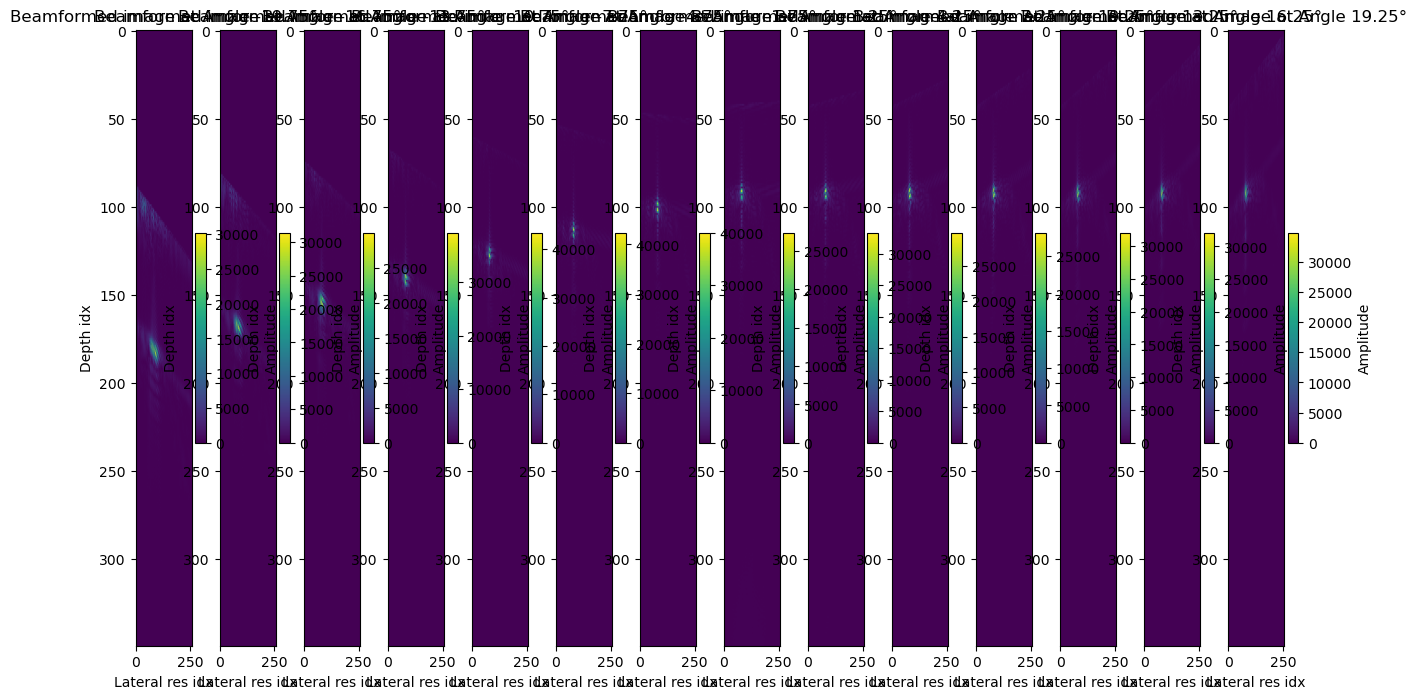

In [314]:

num_angles = bf_matrices.shape[2]
fig, axes = plt.subplots(nrows=1, ncols=num_angles, figsize=(15,8))

if num_angles == 1:
    axes = [axes]

for i in range(num_angles):
    im = axes[i].imshow(np.abs(bf_matrices[:,:,i]), aspect='auto', cmap='viridis')
    axes[i].set_title(f'Beamformed image at Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[i].set_xlabel('Lateral res idx')
    axes[i].set_ylabel('Depth idx')
    fig.colorbar(im, ax=axes[i], label='Amplitude')

plt.tight_layout()
plt.show()

# Get most energy axial profile

In [315]:
def extract_highest_value_region_all_angles(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    max_values = {
        "row": [],
        "col": [],
        "angle": [],
    }

    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

        max_values["row"].append(row)
        max_values["col"].append(col)
        max_values["angle"].append(params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i])

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices, max_values

## Images

Max value at angle -19.75°: 30215.523364642373
Max value row: 107, col: 24


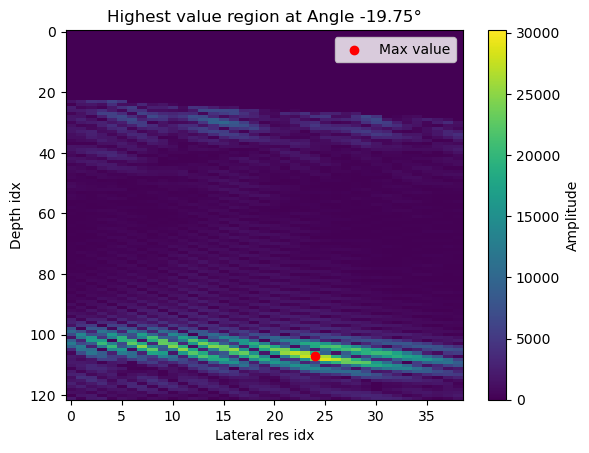

Max value at angle -16.75°: 31423.96540384132
Max value row: 93, col: 21


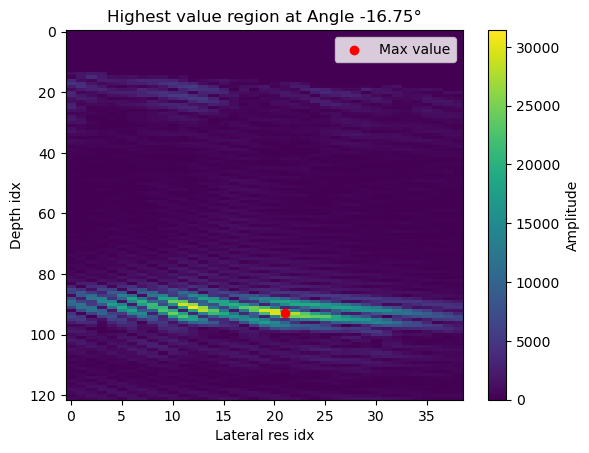

Max value at angle -13.75°: 29967.77922701529
Max value row: 79, col: 16


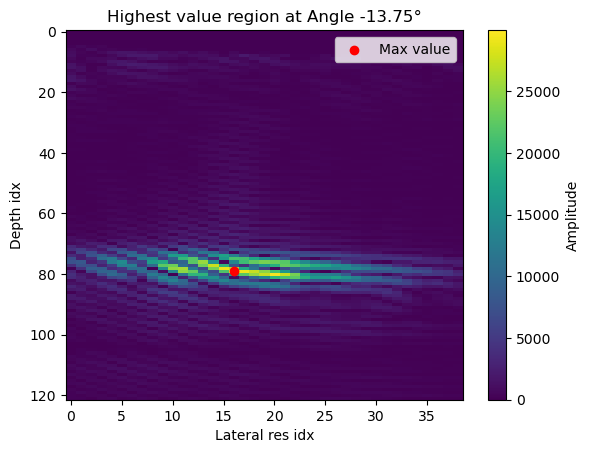

Max value at angle -10.75°: 39203.46556839401
Max value row: 64, col: 17


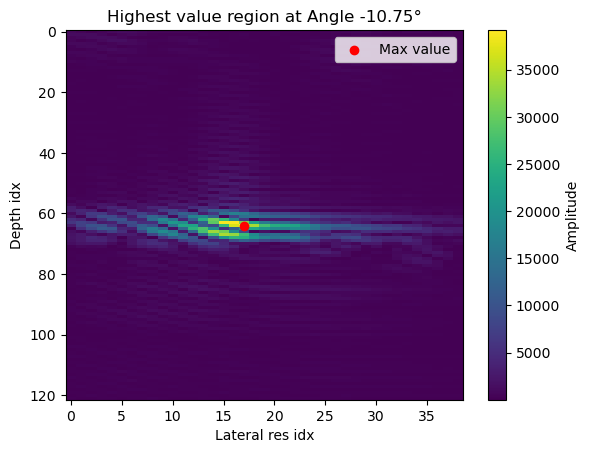

Max value at angle -7.75°: 43399.0912687715
Max value row: 52, col: 16


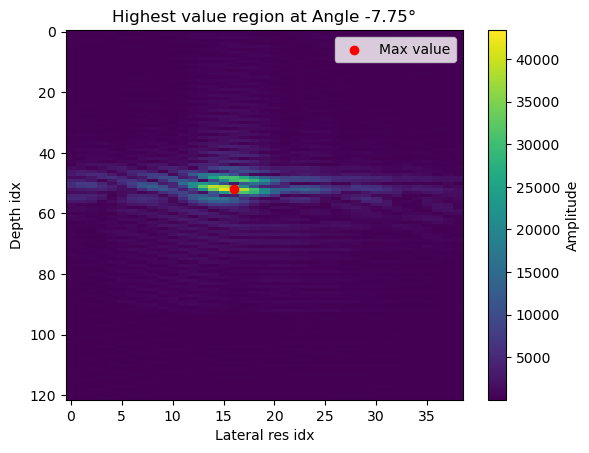

Max value at angle -4.75°: 42382.2377217729
Max value row: 37, col: 16


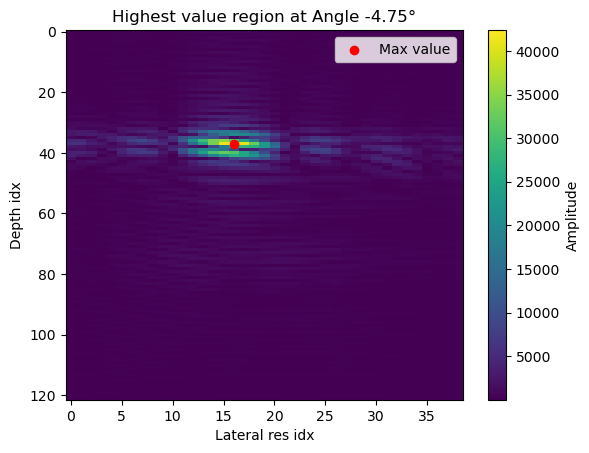

Max value at angle -1.75°: 40010.96437941335
Max value row: 26, col: 16


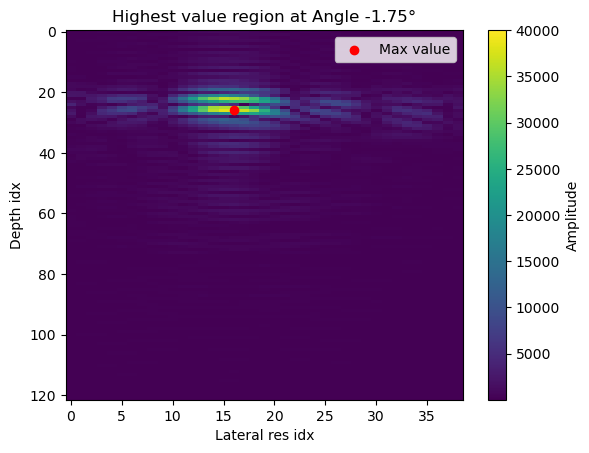

Max value at angle 1.25°: 27368.74262029259
Max value row: 15, col: 15


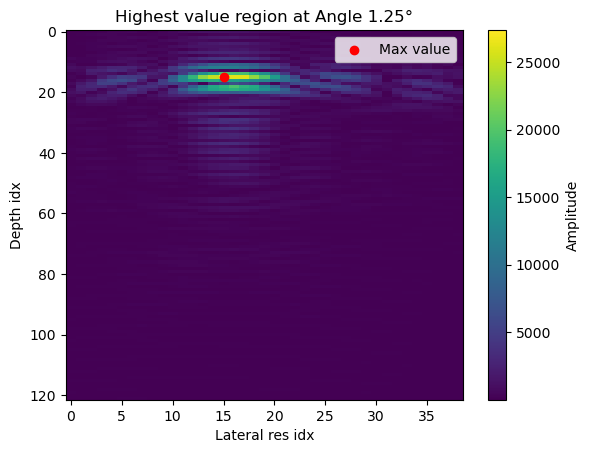

Max value at angle 4.25°: 33339.06941148493
Max value row: 15, col: 15


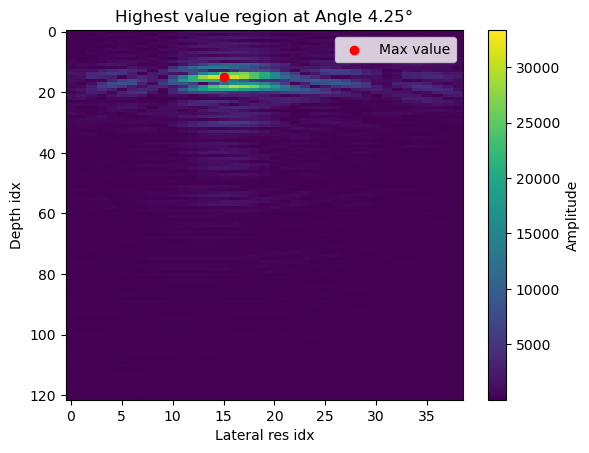

Max value at angle 7.25°: 29701.10953540581
Max value row: 18, col: 16


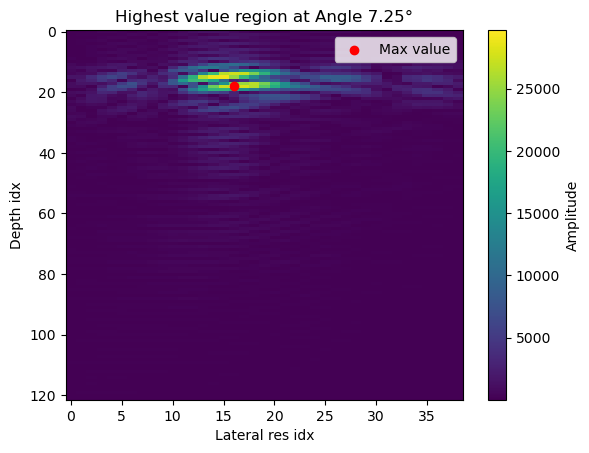

Max value at angle 10.25°: 28140.391675145253
Max value row: 17, col: 17


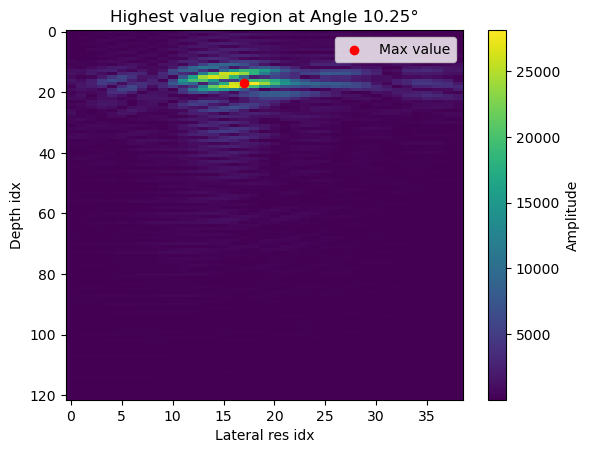

Max value at angle 13.25°: 32061.501136476243
Max value row: 17, col: 16


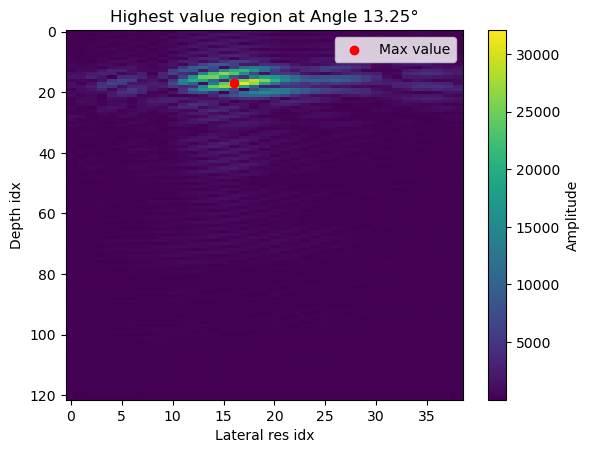

Max value at angle 16.25°: 32103.687405429682
Max value row: 17, col: 16


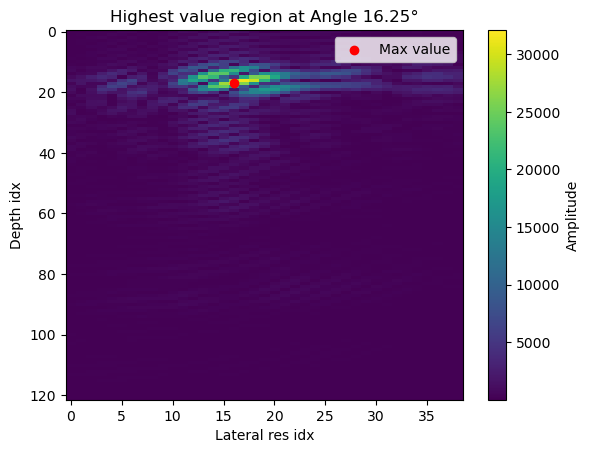

Max value at angle 19.25°: 34802.406577593814
Max value row: 16, col: 16


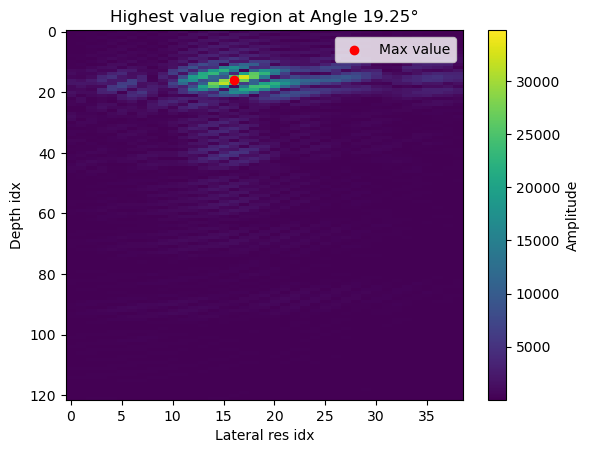

In [316]:
submatrix, max_values = extract_highest_value_region_all_angles(np.abs(bf_matrices), depth_margin= 15, lateral_margin= 15)

for i in range(num_angles):
        
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    
    
    print(f"Max value at angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°: {submatrix[:,:,i][max_val_row, max_val_col]}")
    print(f"Max value row: {max_val_row}, col: {max_val_col}")
    plt.imshow(submatrix[:,:,i], aspect='auto', cmap='viridis')
    plt.title(f'Highest value region at Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    plt.xlabel('Lateral res idx')
    plt.ylabel('Depth idx')
    plt.colorbar(label='Amplitude')
    plt.scatter(max_val_col, max_val_row, color='red', label='Max value')
    plt.legend()
    plt.show()

## Curves

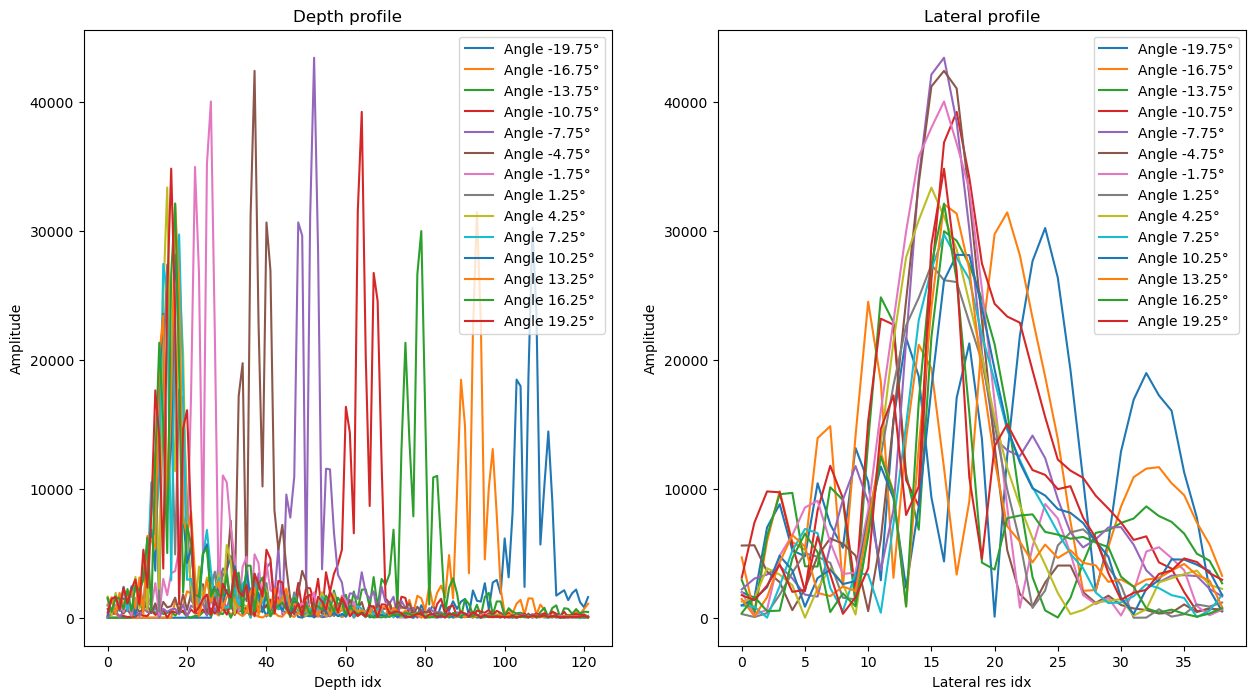

In [317]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,8))

for i in range(submatrix.shape[2]):
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)
    axes[0].plot(submatrix[:,:,i][:,max_val_col], label=f'Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[0].set_title('Depth profile')
    axes[0].set_xlabel('Depth idx')
    axes[0].set_ylabel('Amplitude')
    axes[0].legend()

    axes[1].plot(submatrix[:,:,i][max_val_row,:], label=f'Angle {params["rf"]["angles"][i] if examine_all_angles else angles_to_study[i]}°')
    axes[1].set_title('Lateral profile')
    axes[1].set_xlabel('Lateral res idx')
    axes[1].set_ylabel('Amplitude')
    axes[1].legend()

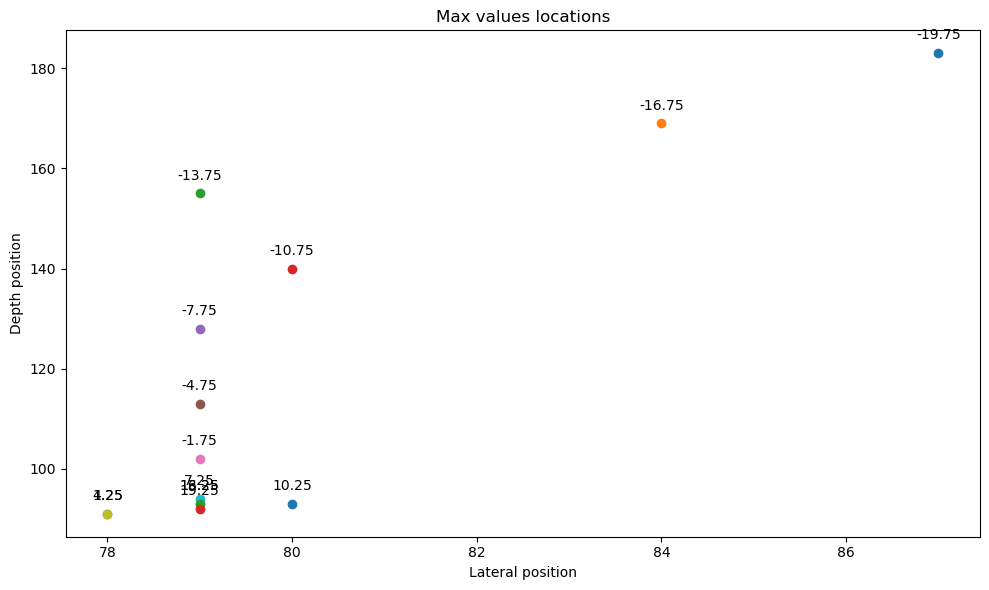

In [318]:
plt.figure(figsize=(10,6))  
for i in range(len(max_values["angle"])):
    plt.scatter(max_values["col"][i], max_values["row"][i])
    plt.annotate(max_values["angle"][i], (max_values["col"][i], max_values["row"][i]), textcoords="offset points", xytext=(0,10), ha='center')
plt.title('Max values locations')
plt.xlabel('Lateral position')
plt.ylabel('Depth position')
plt.tight_layout()
plt.show()


# plt.scatter(max_values["col"], max_values["row"], label=max_values["angle"], color='red')

In [319]:
test_bf = bf_matrices[:,:,0:7]

In [320]:
bf_matrices_summed = np.sum(test_bf, axis = 2)

In [321]:
bf_matrices_summed.shape

(350, 256)

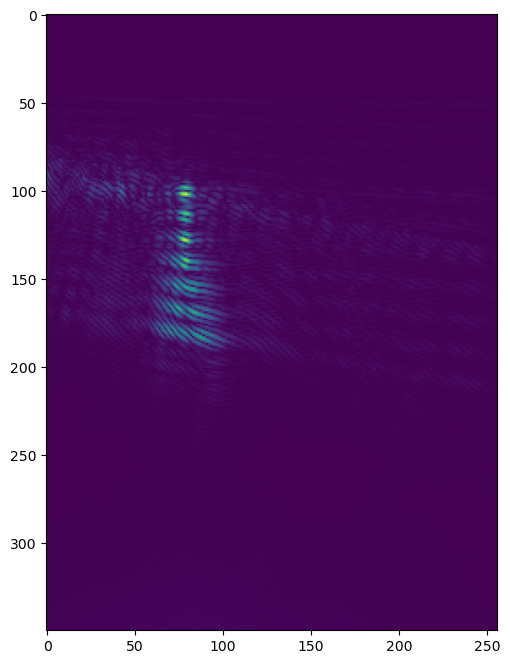

In [322]:
plt.figure(figsize=(10,8))
plt.imshow(np.abs(bf_matrices_summed))